# SecondLook | 01 Exploratory Data Analysis (EDA)

**Group 3 Capstone, Uplift Code Camp: Python for Data and AI**

**Business question:** *Among applicants a lender would decline, which ones are actually safe to approve, and what realistic changes would get the rest approved?*

Before we build any model, we need to understand the data we are working with. This notebook answers five questions:

1. **What is in the data?** Tables, rows, columns and data types.
2. **How clean is it?** Missing values, duplicates, impossible values and outliers.
3. **What does the target look like?** How many applicants actually defaulted.
4. **Which factors are related to default?** Using charts *and* statistical tests, so we don't rely on what "looks" different.
5. **What does this mean for modelling and for the app?** Each finding ends with a concrete decision.

**Dataset:** [Home Credit Default Risk (Kaggle)](https://www.kaggle.com/competitions/home-credit-default-risk/data). Home Credit lends to people with little or no credit history, which is exactly the thin-file population SecondLook is designed for.

| Section | Bootcamp topic |
|---|---|
| 1–2 Setup and overview | Python foundations, file handling, Pandas |
| 3 Types of data | Categorical vs numerical, scales of measurement, independent vs dependent variables |
| 4–5 Target and data quality | Missing data, duplicates, data type correction |
| 6–7 Descriptive statistics, distributions, outliers | Mean/median/mode, variance, percentiles, skewness and kurtosis, IQR |
| 8–10 Relationships with default | Matplotlib and Seaborn, hypothesis testing (chi-square, t-test, Mann-Whitney), correlation |
| 11 History tables | Merging and aggregating datasets |
| 12 Key insights | Drawing insights from EDA |

## 1. Setup

We import the libraries we need and our own helper package, `secondlook`, which lives in `src/`.

**Why a helper package?** The dataset is a 722 MB zip that unpacks to about 2.7 GB. Instead of extracting it, `load_table()` reads each CSV directly from inside the zip. Every notebook and the Streamlit app use the same function, so we all load data the same way.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Find the project root (the folder that contains src/) and make our package importable
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "secondlook").exists())
sys.path.insert(0, str(ROOT / "src"))

from secondlook.config import FIGURES_DIR, TARGET_COL, ID_COL
from secondlook.data import list_tables, load_table

# Display and chart settings
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    # Save every chart to reports/figures so we can reuse it in the README and the pitch.
    fig.savefig(FIGURES_DIR / f"{name}.png", bbox_inches="tight")

print("Project root:", ROOT)

Project root: C:\Users\Patrick\Desktop\CodeCamp\Group 3 - Capstone Project


## 2. Data overview

### 2.1 What tables do we have?

The data is **relational**: one main table plus six history tables, linked by ID keys (the same idea as primary and foreign keys in SQL).

In [2]:
list_tables()

,table,size_mb
0,HomeCredit_columns_description,0.00
1,POS_CASH_balance,392.70
2,application_test,26.60
3,application_train,166.10
4,bureau,170.00
5,bureau_balance,375.60
6,credit_card_balance,424.60
7,installments_payments,723.10
8,previous_application,405.00
9,sample_submission,0.50


**How the tables connect:**

| Table | One row per | Join key | What it tells us |
|---|---|---|---|
| `application_train` | Current loan application (**has the TARGET**) | `SK_ID_CURR` | Applicant profile: income, loan amount, family, job, external scores |
| `bureau` | Previous loan at *other* lenders | `SK_ID_CURR` → `SK_ID_BUREAU` | Credit history outside Home Credit |
| `bureau_balance` | Month of a bureau loan | `SK_ID_BUREAU` | Monthly status of those loans |
| `previous_application` | Previous Home Credit application | `SK_ID_CURR` → `SK_ID_PREV` | Past approvals and refusals |
| `POS_CASH_balance`, `credit_card_balance` | Month of a previous Home Credit loan or card | `SK_ID_PREV` | Monthly balances |
| `installments_payments` | Installment paid (or missed) | `SK_ID_PREV` | Repayment behaviour: on time or late |

`application_test` has no TARGET (it was Kaggle's scoring set), so **we use `application_train` for all analysis and modelling**. The history tables (`installments_payments` alone is 723 MB) are explored in Section 11, loading only the columns we need.

### 2.2 Load the main table

In [3]:
app = load_table("application_train")

print(f"Rows: {app.shape[0]:,}   Columns: {app.shape[1]}")
print(f"Memory: {app.memory_usage(deep=True).sum() / 1e6:,.0f} MB")
app.head()

Rows: 307,511   Columns: 122


Memory: 530 MB


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,...,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,"202,500.00","406,597.50","24,700.50","351,000.00",Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.02,-9461,-637,"-3,648.00",-2120,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00,1.00
1,100003,0,Cash loans,F,N,N,0,"270,000.00","1,293,502.50","35,698.50","1,129,500.00",Family,State servant,Higher education,Married,House / apartment,0.00,-16765,-1188,"-1,186.00",-291,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00,0.00
2,100004,0,Revolving loans,M,Y,Y,0,"67,500.00","135,000.00","6,750.00","135,000.00",Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.01,-19046,-225,"-4,260.00",-2531,26.00,1,1,1,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00,0.00
3,100006,0,Cash loans,F,N,Y,0,"135,000.00","312,682.50","29,686.50","297,000.00",Unaccompanied,Working,Secondary / secondary special,Civil marriage,House / apartment,0.01,-19005,-3039,"-9,833.00",-2437,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,"121,500.00","513,000.00","21,865.50","513,000.00",Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.03,-19932,-3038,"-4,311.00",-3458,NaN,1,1,0,...,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00,0.00


**What we see:** 307,511 applicants and 122 columns, about 530 MB in memory. Each row is one loan application. `TARGET` is what we want to predict, and the remaining columns describe the applicant and the loan.

The column names are not always self-explanatory (e.g. `EXT_SOURCE_2`, `DAYS_BIRTH`), so we also load the official data dictionary.

In [4]:
dictionary = load_table("HomeCredit_columns_description")
key_cols = ["TARGET", "DAYS_BIRTH", "DAYS_EMPLOYED", "EXT_SOURCE_1", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE"]
(dictionary[dictionary["Table"].eq("application_{train|test}.csv") & dictionary["Row"].isin(key_cols)]
 [["Row", "Description"]].set_index("Row"))

,Description
Row,
TARGET,Target variable (1 - client with payment diffi...
AMT_CREDIT,Credit amount of the loan
AMT_ANNUITY,Loan annuity
AMT_GOODS_PRICE,For consumer loans it is the price of the good...
DAYS_BIRTH,Client's age in days at the time of application
DAYS_EMPLOYED,How many days before the application the perso...
EXT_SOURCE_1,Normalized score from external data source


**Two important details from the dictionary:**

- **`DAYS_*` columns are negative**: they count days *before* the application date. For example, `DAYS_BIRTH = -12,000` means the applicant was about 33 years old. We will convert these to years.
- **`EXT_SOURCE_1/2/3`** are *normalized scores from external data sources* (similar to credit scores from other agencies), on a 0–1 scale. We expect them to be strong predictors.

## 3. Types of data and variables

Knowing the **type** of each variable decides which charts, statistics and tests we can use. For example, a mean makes sense for income but not for education level, and we use a chi-square test for categorical variables but a t-test for numerical ones.

In [5]:
print(app.dtypes.value_counts().rename("number of columns").to_string())

categorical = app.select_dtypes("object").columns.tolist()
print(f"\n{len(categorical)} text (categorical) columns:", categorical)

float64    65
int64      41
object     16

16 text (categorical) columns: ['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']


**What we see:** 106 numeric columns and 16 text columns. But pandas dtype alone is misleading: many "numeric" columns are really categories stored as 0/1 flags (e.g. `FLAG_OWN_CAR`, `FLAG_DOCUMENT_3`) or ratings (`REGION_RATING_CLIENT` = 1, 2, 3).

Here is how the key variables classify, using the bootcamp's framework:

| Variable | Type | Scale of measurement | Example values |
|---|---|---|---|
| `TARGET` | Categorical (binary) | Nominal | 0 = repaid, 1 = had payment difficulties |
| `CODE_GENDER`, `NAME_FAMILY_STATUS`, `OCCUPATION_TYPE` | Categorical | Nominal (no natural order) | F/M; Married, Single… |
| `NAME_EDUCATION_TYPE` | Categorical | **Ordinal** (has an order) | Lower secondary < Secondary < Higher education |
| `REGION_RATING_CLIENT` | Categorical | Ordinal | 1 (best region) to 3 |
| `CNT_CHILDREN` | Numerical, **discrete** (counts) | Ratio | 0, 1, 2… |
| `AMT_INCOME_TOTAL`, `AMT_CREDIT` | Numerical, **continuous** | **Ratio** (true zero; ₱200k is twice ₱100k) | 147,150 |
| `DAYS_BIRTH` → age in years | Numerical, continuous | Ratio | 43.1 years |
| `EXT_SOURCE_1/2/3` | Numerical, continuous | Interval-like score (0–1) | 0.51 |

**Dependent vs independent variables:** `TARGET` is the **dependent variable** (what we want to explain and predict). Everything else is a candidate **independent variable** (a feature). `SK_ID_CURR` is just an ID and carries no information.

## 4. The target variable: how many applicants defaulted?

This is the most important single chart in the EDA, because it decides how we must evaluate the model.

,applicants,share_%
0 = Repaid,282686,91.93
1 = Payment difficulties,24825,8.07


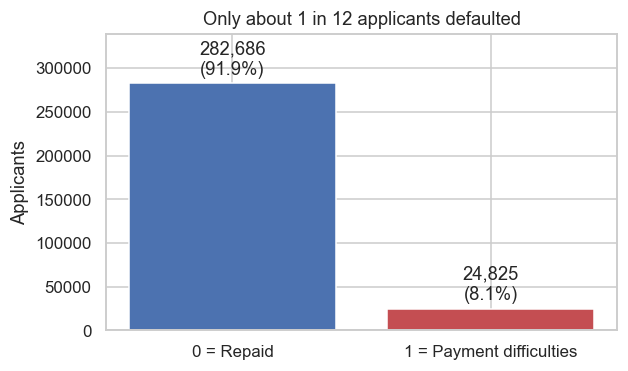

In [6]:
counts = app[TARGET_COL].value_counts().sort_index()
share = app[TARGET_COL].value_counts(normalize=True).sort_index() * 100
summary = pd.DataFrame({"applicants": counts, "share_%": share})
summary.index = ["0 = Repaid", "1 = Payment difficulties"]
display(summary)

fig, ax = plt.subplots(figsize=(6, 3.5))
bars = ax.bar(summary.index, summary["applicants"], color=["#4C72B0", "#C44E52"])
ax.bar_label(bars, labels=[f"{n:,}\n({p:.1f}%)" for n, p in zip(summary["applicants"], summary["share_%"])], padding=3)
ax.set_title("Only about 1 in 12 applicants defaulted")
ax.set_ylabel("Applicants")
ax.set_ylim(0, counts.max() * 1.2)
save(fig, "01_target_distribution")
plt.show()

**Interpretation:** 24,825 of 307,511 applicants (**8.07%**) had payment difficulties, while 91.93% repaid. The classes are **heavily imbalanced** (about 11 repaid for every 1 default).

**Why this matters:**
- **Accuracy is a misleading metric here.** A "model" that predicts *everyone repays* would be 91.9% accurate while catching zero defaulters. We will evaluate with **ROC AUC, precision and recall** instead.
- When we split the data into train and test sets, we must use a **stratified split** so both sets keep the same 8% default rate.
- During training we will give the minority class more weight so the model doesn't ignore it.

## 5. Data quality

Real data is messy. Before trusting any statistic, we check four things: **duplicates, missing values, impossible values and inconsistent categories.**

### 5.1 Duplicates

In [7]:
print("Fully duplicated rows:      ", app.duplicated().sum())
print("Duplicated applicant IDs:   ", app[ID_COL].duplicated().sum())

Fully duplicated rows:       0
Duplicated applicant IDs:    0


**Interpretation:** No duplicates. Each applicant appears exactly once, so `SK_ID_CURR` is a valid **primary key** we can safely join the history tables on.

### 5.2 Missing values

Columns with any missing values: 67 of 122
Columns more than 50% missing:   41


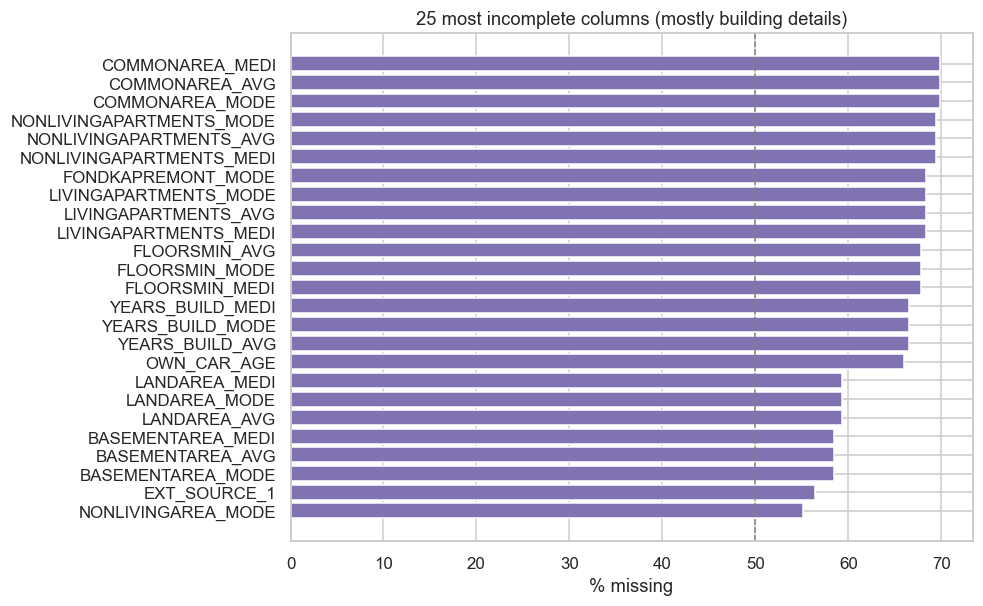

In [8]:
missing = (app.isna().mean() * 100).sort_values(ascending=False)
missing = missing[missing > 0]

print(f"Columns with any missing values: {len(missing)} of {app.shape[1]}")
print(f"Columns more than 50% missing:   {(missing > 50).sum()}")

fig, ax = plt.subplots(figsize=(8, 6))
top = missing.head(25)[::-1]
ax.barh(top.index, top.values, color="#8172B2")
ax.axvline(50, color="grey", ls="--", lw=1)
ax.set_xlabel("% missing")
ax.set_title("25 most incomplete columns (mostly building details)")
save(fig, "02_missing_values")
plt.show()

In [9]:
# Missingness of columns we expect to matter most
important = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "OCCUPATION_TYPE", "OWN_CAR_AGE", "AMT_ANNUITY", "AMT_GOODS_PRICE"]
missing.reindex(important).fillna(0).round(1).rename("% missing").to_frame()

,% missing
EXT_SOURCE_1,56.40
EXT_SOURCE_2,0.20
EXT_SOURCE_3,19.80
OCCUPATION_TYPE,31.30
OWN_CAR_AGE,66.00
AMT_ANNUITY,0.00
AMT_GOODS_PRICE,0.10


**Interpretation:**
- **67 of 122 columns** have missing values, and **41 are more than half empty**.
- The worst offenders (`COMMONAREA_*`, `LIVINGAPARTMENTS_*`, `FLOORSMIN_*`…, around 68–70% missing) all describe the **applicant's building**. They are missing together, which suggests the lender simply didn't collect housing details for many applicants.
- Among the important columns: `EXT_SOURCE_1` is **56% missing** and `EXT_SOURCE_3` **20%**, while `EXT_SOURCE_2` is almost complete. `OCCUPATION_TYPE` is 31% missing. `OWN_CAR_AGE` is 66% missing, but that's expected: people without a car have no car age.

**Decisions (missing-data strategy):**
- **Don't delete rows**: almost every applicant has *something* missing, so we would lose most of the data.
- **Keep "missing" as information.** For a lender, having no external score is itself a signal (a thin file). LightGBM handles missing values natively, and for the logistic regression baseline we will **impute** (median for numbers, "Unknown" for categories) and add *is-missing* flags for key columns.
- Building columns: keep only a few summary ones (e.g. `*_AVG`), since the `_MODE` and `_MEDI` versions are near-copies.

### 5.3 Impossible values: the `DAYS_EMPLOYED` anomaly

`DAYS_EMPLOYED` should be negative (days employed *before* applying). Let's check its range.

In [10]:
print(app["DAYS_EMPLOYED"].describe().to_string())

anomaly = app["DAYS_EMPLOYED"].eq(365243)
print(f"\nRows with DAYS_EMPLOYED = 365243: {anomaly.sum():,} ({anomaly.mean():.1%})")
print("\nIncome type of those rows:")
print(app.loc[anomaly, "NAME_INCOME_TYPE"].value_counts().to_string())
print(f"\nDefault rate | anomaly rows: {app.loc[anomaly, TARGET_COL].mean():.2%}   other rows: {app.loc[~anomaly, TARGET_COL].mean():.2%}")

count   307,511.00
mean     63,815.05
std     141,275.77
min     -17,912.00
25%      -2,760.00
50%      -1,213.00
75%        -289.00
max     365,243.00

Rows with DAYS_EMPLOYED = 365243: 55,374 (18.0%)

Income type of those rows:
NAME_INCOME_TYPE
Pensioner     55352
Unemployed       22

Default rate | anomaly rows: 5.40%   other rows: 8.66%


**Interpretation:** The maximum is **365,243 days, i.e. 1,000 years** of employment, which is impossible. It appears in **55,374 rows (18%)**, and almost all of them are **pensioners** (plus 22 unemployed). This is a **placeholder code** meaning "not currently employed", not a real number.

These applicants are also **less risky** (5.4% default vs 8.66%), so the placeholder carries real information.

**Decision:** replace 365,243 with *missing* (so it doesn't distort averages or the model's sense of scale) and add a flag column `DAYS_EMPLOYED_ANOM` so the information isn't lost. Below we apply this, and convert the negative day counts into positive years.

In [11]:
app["DAYS_EMPLOYED_ANOM"] = anomaly.astype(int)
app["DAYS_EMPLOYED"] = app["DAYS_EMPLOYED"].where(~anomaly)          # 365243 -> NaN

# Data type correction: negative day counts -> positive years (easier to read and explain)
app["AGE_YEARS"] = -app["DAYS_BIRTH"] / 365.25
app["YEARS_EMPLOYED"] = app["DAYS_EMPLOYED"].abs() / 365.25

app[["AGE_YEARS", "YEARS_EMPLOYED"]].describe().T

,count,mean,std,min,25%,50%,75%,max
AGE_YEARS,"307,511.00",43.91,11.95,20.50,33.98,43.12,53.89,69.07
YEARS_EMPLOYED,"252,137.00",6.53,6.40,0.00,2.10,4.51,8.69,49.04


**Result:** applicants are between **20.5 and 69 years old** (average 43.9), and among those employed the average tenure is **6.5 years**. Both now look realistic.

### 5.4 Inconsistent categories

In [12]:
# Look for placeholder category values such as "XNA" (= not available)
for col in categorical:
    vc = app[col].value_counts()
    if "XNA" in vc.index:
        print(f"{col:20s} XNA rows: {vc['XNA']:,}")
print("\nCODE_GENDER values:", app["CODE_GENDER"].value_counts().to_dict())

CODE_GENDER          XNA rows: 4


ORGANIZATION_TYPE    XNA rows: 55,374

CODE_GENDER values: {'F': 202448, 'M': 105059, 'XNA': 4}


**Interpretation:**
- `CODE_GENDER` has **4 rows with "XNA"** (unknown). That's too few to learn from, so we will set them to missing.
- `ORGANIZATION_TYPE` has **55,374 "XNA"** rows: exactly the same count as the pensioner anomaly above. It's the same group (people with no employer), so "XNA" here really means *no employer* and we will keep it as its own category.

## 6. Descriptive statistics

Now that the obvious errors are handled, we summarize the main numerical variables with **measures of central tendency** (mean, median, mode) and **measures of spread** (range, variance, standard deviation, percentiles).

In [13]:
num_cols = ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE", "AGE_YEARS", "YEARS_EMPLOYED", "CNT_CHILDREN"]

desc = app[num_cols].describe(percentiles=[0.25, 0.5, 0.75, 0.99]).T
desc["mode"] = [app[c].mode().iloc[0] for c in num_cols]
desc["range"] = desc["max"] - desc["min"]
desc["variance"] = app[num_cols].var()
desc[["count", "mean", "50%", "mode", "std", "variance", "min", "25%", "75%", "99%", "max", "range"]]

,count,mean,50%,mode,std,variance,min,25%,75%,99%,max,range
AMT_INCOME_TOTAL,"307,511.00","168,797.92","147,150.00","135,000.00","237,123.15","56,227,386,501.17","25,650.00","112,500.00","202,500.00","472,500.00","117,000,000.00","116,974,350.00"
AMT_CREDIT,"307,511.00","599,026.00","513,531.00","450,000.00","402,490.78","161,998,825,566.80","45,000.00","270,000.00","808,650.00","1,854,000.00","4,050,000.00","4,005,000.00"
AMT_ANNUITY,"307,499.00","27,108.57","24,903.00","9,000.00","14,493.74","210,068,421.36","1,615.50","16,524.00","34,596.00","70,006.50","258,025.50","256,410.00"
AMT_GOODS_PRICE,"307,233.00","538,396.21","450,000.00","450,000.00","369,446.46","136,490,687,205.54","40,500.00","238,500.00","679,500.00","1,800,000.00","4,050,000.00","4,009,500.00"
AGE_YEARS,"307,511.00",43.91,43.12,37.64,11.95,142.75,20.50,33.98,53.89,66.86,69.07,48.57
YEARS_EMPLOYED,"252,137.00",6.53,4.51,0.55,6.40,40.99,0.00,2.10,8.69,31.04,49.04,49.04
CNT_CHILDREN,"307,511.00",0.42,0.00,0.00,0.72,0.52,0.00,0.00,1.00,3.00,19.00,19.00


**Interpretation (amounts are in the dataset's local currency):**

- **Income:** the **mean (168,798) is higher than the median (147,150)**, and the median is higher than the mode (135,000). Mean > median > mode is the signature of a **right-skewed** distribution: a few very high earners pull the average up. The maximum is **117,000,000**, about 800× the median and almost certainly a data-entry error, while 99% of applicants earn 472,500 or less. **The median is the better "typical" income here.**
- **Loan amount (`AMT_CREDIT`):** median 513,531, mean 599,026, also right-skewed but much less extreme. A typical loan is about **3.3× annual income**.
- **Annuity (`AMT_ANNUITY`):** the regular repayment amount on the loan; the median is 24,903.
- **Age:** mean (43.9) ≈ median (43.1), so age is roughly **symmetric**, spread fairly evenly between about 34 and 54 (the middle 50%).
- **Children:** the median is 0, and 75% of applicants have one child or fewer, with a maximum of 19.
- `AMT_CREDIT` and `AMT_GOODS_PRICE` (price of the item being financed) have very similar statistics, which we check in Section 10.

## 7. Distributions and outliers

### 7.1 Shape of the distributions: skewness and kurtosis

- **Skewness** measures asymmetry: 0 = symmetric (like a normal bell curve), positive = long tail to the right.
- **Kurtosis** (excess) measures how heavy the tails are: 0 = like a normal distribution, high = many extreme values.

In [14]:
shape = pd.DataFrame({"skewness": app[num_cols].skew(), "kurtosis": app[num_cols].kurt()})
shape

,skewness,kurtosis
AMT_INCOME_TOTAL,391.56,"191,786.55"
AMT_CREDIT,1.23,1.93
AMT_ANNUITY,1.58,7.71
AMT_GOODS_PRICE,1.35,2.43
AGE_YEARS,0.12,-1.05
YEARS_EMPLOYED,1.97,4.75
CNT_CHILDREN,1.97,7.90


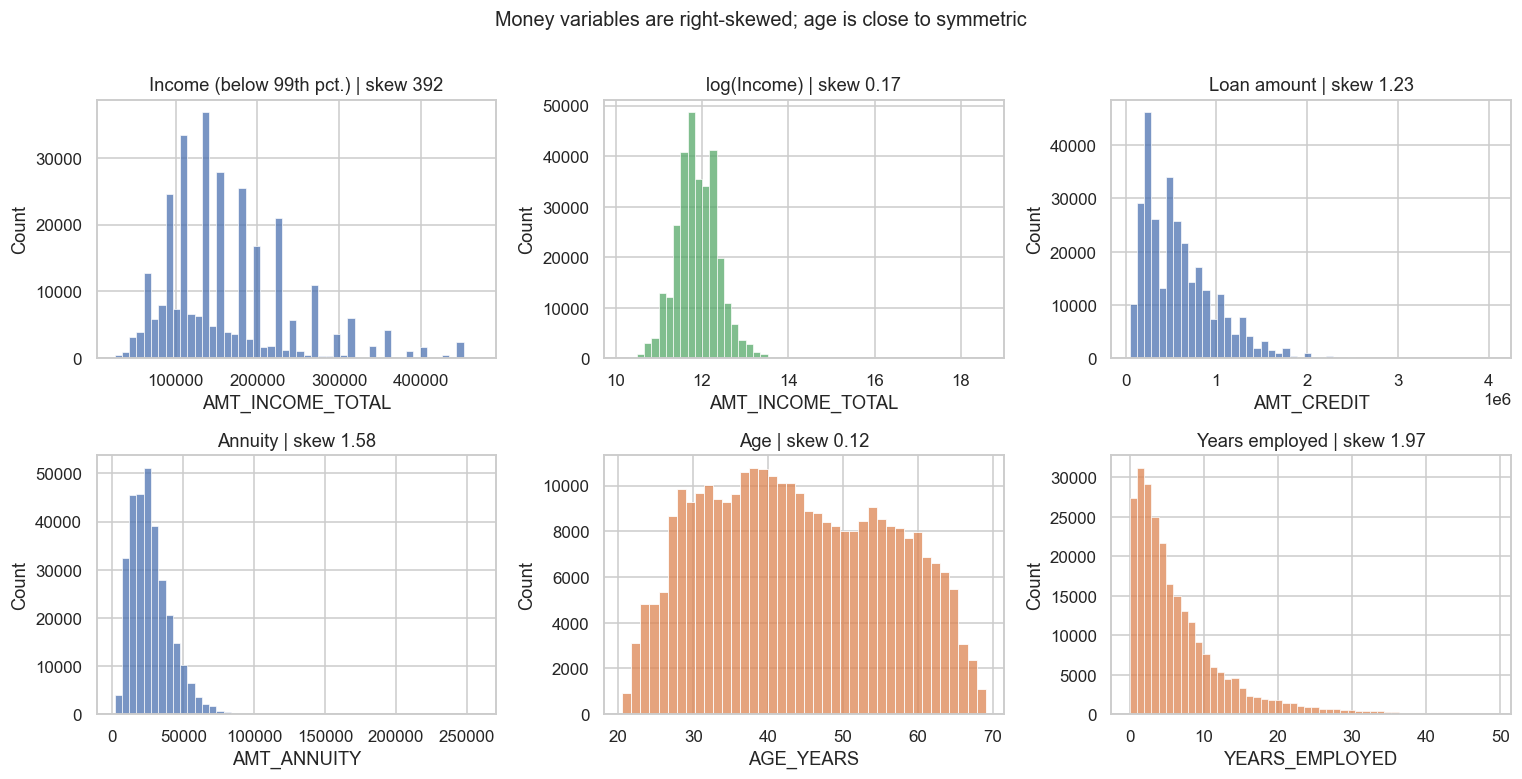

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))

# Income: raw vs log scale (clip at the 99th percentile so the chart is readable)
inc = app["AMT_INCOME_TOTAL"]
sns.histplot(inc[inc < inc.quantile(0.99)], bins=50, ax=axes[0, 0], color="#4C72B0")
axes[0, 0].set_title(f"Income (below 99th pct.) | skew {inc.skew():,.0f}")
sns.histplot(np.log1p(inc), bins=50, ax=axes[0, 1], color="#55A868")
axes[0, 1].set_title(f"log(Income) | skew {np.log1p(inc).skew():.2f}")

sns.histplot(app["AMT_CREDIT"], bins=50, ax=axes[0, 2], color="#4C72B0")
axes[0, 2].set_title(f"Loan amount | skew {app['AMT_CREDIT'].skew():.2f}")
sns.histplot(app["AMT_ANNUITY"], bins=50, ax=axes[1, 0], color="#4C72B0")
axes[1, 0].set_title(f"Annuity | skew {app['AMT_ANNUITY'].skew():.2f}")
sns.histplot(app["AGE_YEARS"], bins=40, ax=axes[1, 1], color="#DD8452")
axes[1, 1].set_title(f"Age | skew {app['AGE_YEARS'].skew():.2f}")
sns.histplot(app["YEARS_EMPLOYED"].dropna(), bins=50, ax=axes[1, 2], color="#DD8452")
axes[1, 2].set_title(f"Years employed | skew {app['YEARS_EMPLOYED'].skew():.2f}")

fig.suptitle("Money variables are right-skewed; age is close to symmetric", y=1.01, fontsize=13)
fig.tight_layout()
save(fig, "03_distributions")
plt.show()

**Interpretation:**
- **Income** is extremely skewed (skewness **≈ 392**, kurtosis **≈ 191,787**), driven by the 117 million outlier. After a **log transform**, skewness drops to **0.17**, almost symmetric. We will use log(income) in linear models and in ratios.
- **Loan amount and annuity** are moderately right-skewed (skewness 1.2–1.6): most loans are small or medium, with fewer large ones. The spikes in the loan histogram are popular round amounts (e.g. 450,000).
- **Age** is close to symmetric (skewness **0.12**) and flat-topped (kurtosis **−1.05**): applicants are spread evenly across working ages, not clustered around one age.
- **Years employed** is right-skewed: many applicants have short job tenure.

**Decision:** tree models like LightGBM are not affected by skew, but for logistic regression we will **log-transform the money columns**.

### 7.2 Outliers with the IQR method

An outlier is a value below **Q1 − 1.5 × IQR** or above **Q3 + 1.5 × IQR**, where IQR = Q3 − Q1 (the range of the middle 50%). The question isn't just *are there outliers*, but *are they errors or real, meaningful customers?*

In [16]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (s < low) | (s > high)
    return low, high, mask

rows = []
for col in ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "CNT_CHILDREN", "AGE_YEARS"]:
    s = app[col].dropna()
    low, high, mask = iqr_outliers(s)
    rows.append({"column": col, "lower fence": low, "upper fence": high,
                 "outliers": mask.sum(), "% of rows": mask.mean() * 100,
                 "default rate of outliers %": app.loc[s[mask].index, TARGET_COL].mean() * 100})
outliers = pd.DataFrame(rows).set_index("column")
outliers

,lower fence,upper fence,outliers,% of rows,default rate of outliers %
column,,,,,
AMT_INCOME_TOTAL,"-22,500.00","337,500.00",14035,4.56,5.81
AMT_CREDIT,"-537,975.00","1,616,625.00",6562,2.13,4.11
AMT_ANNUITY,"-10,584.00","61,704.00",7504,2.44,4.12
CNT_CHILDREN,-1.50,2.50,4272,1.39,10.04
AGE_YEARS,4.13,83.74,0,0.00,NaN


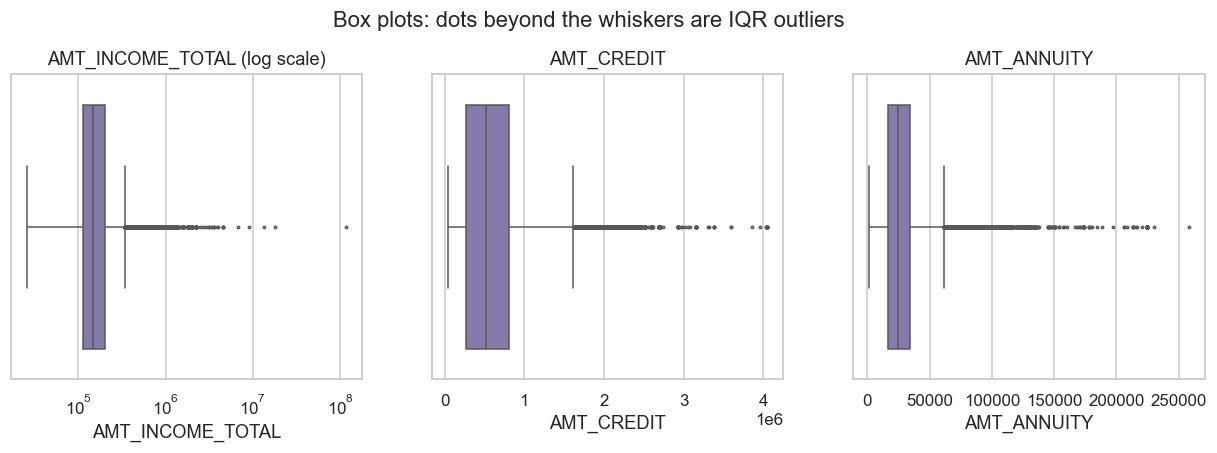

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, col in zip(axes, ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY"]):
    sns.boxplot(x=app[col], ax=ax, color="#8172B2", fliersize=1.5)
    ax.set_title(col)
axes[0].set_xscale("log")
axes[0].set_title("AMT_INCOME_TOTAL (log scale)")
fig.suptitle("Box plots: dots beyond the whiskers are IQR outliers", y=1.04)
save(fig, "04_outliers_boxplots")
plt.show()

**Interpretation:**
- **Income:** 14,035 applicants (**4.6%**) earn above the upper fence of 337,500. Their default rate is **5.8%**, *lower* than average, so they are mostly genuine high earners, not errors. Only the extreme 117 million value is clearly a mistake.
- **Loan amount and annuity:** about 2% outliers each, also with **lower** default rates (about 4.1%). Large loans tend to go to stronger applicants.
- **Children:** 4,272 applicants (1.4%) have 3 or more children, and their default rate is **10.0%**, *higher* than average. A real and meaningful group.
- **Age:** no outliers; every age falls between 20 and 69.

**Decision:** **don't delete outliers.** They are real customers, and several groups behave differently in ways the model should learn. We will only **cap income at the 99.9th percentile** to neutralize the 117 million data-entry error.

## 8. Which categories default more? (Categorical variables vs TARGET)

For each categorical variable, we compare the **default rate** of each group with the overall rate of 8.07%.

Because a difference in a chart could just be random noise, we confirm it with a **chi-square test of independence**:
- **H₀ (null hypothesis):** the category and default are independent (no relationship).
- **H₁:** they are related.
- If **p < 0.05**, we reject H₀.

With 300,000 rows, even tiny differences come out "significant", so we also report **Cramér's V**, which measures *how strong* the relationship is (0 = none, 0.1 = weak, 0.3 = moderate, 0.5+ = strong).

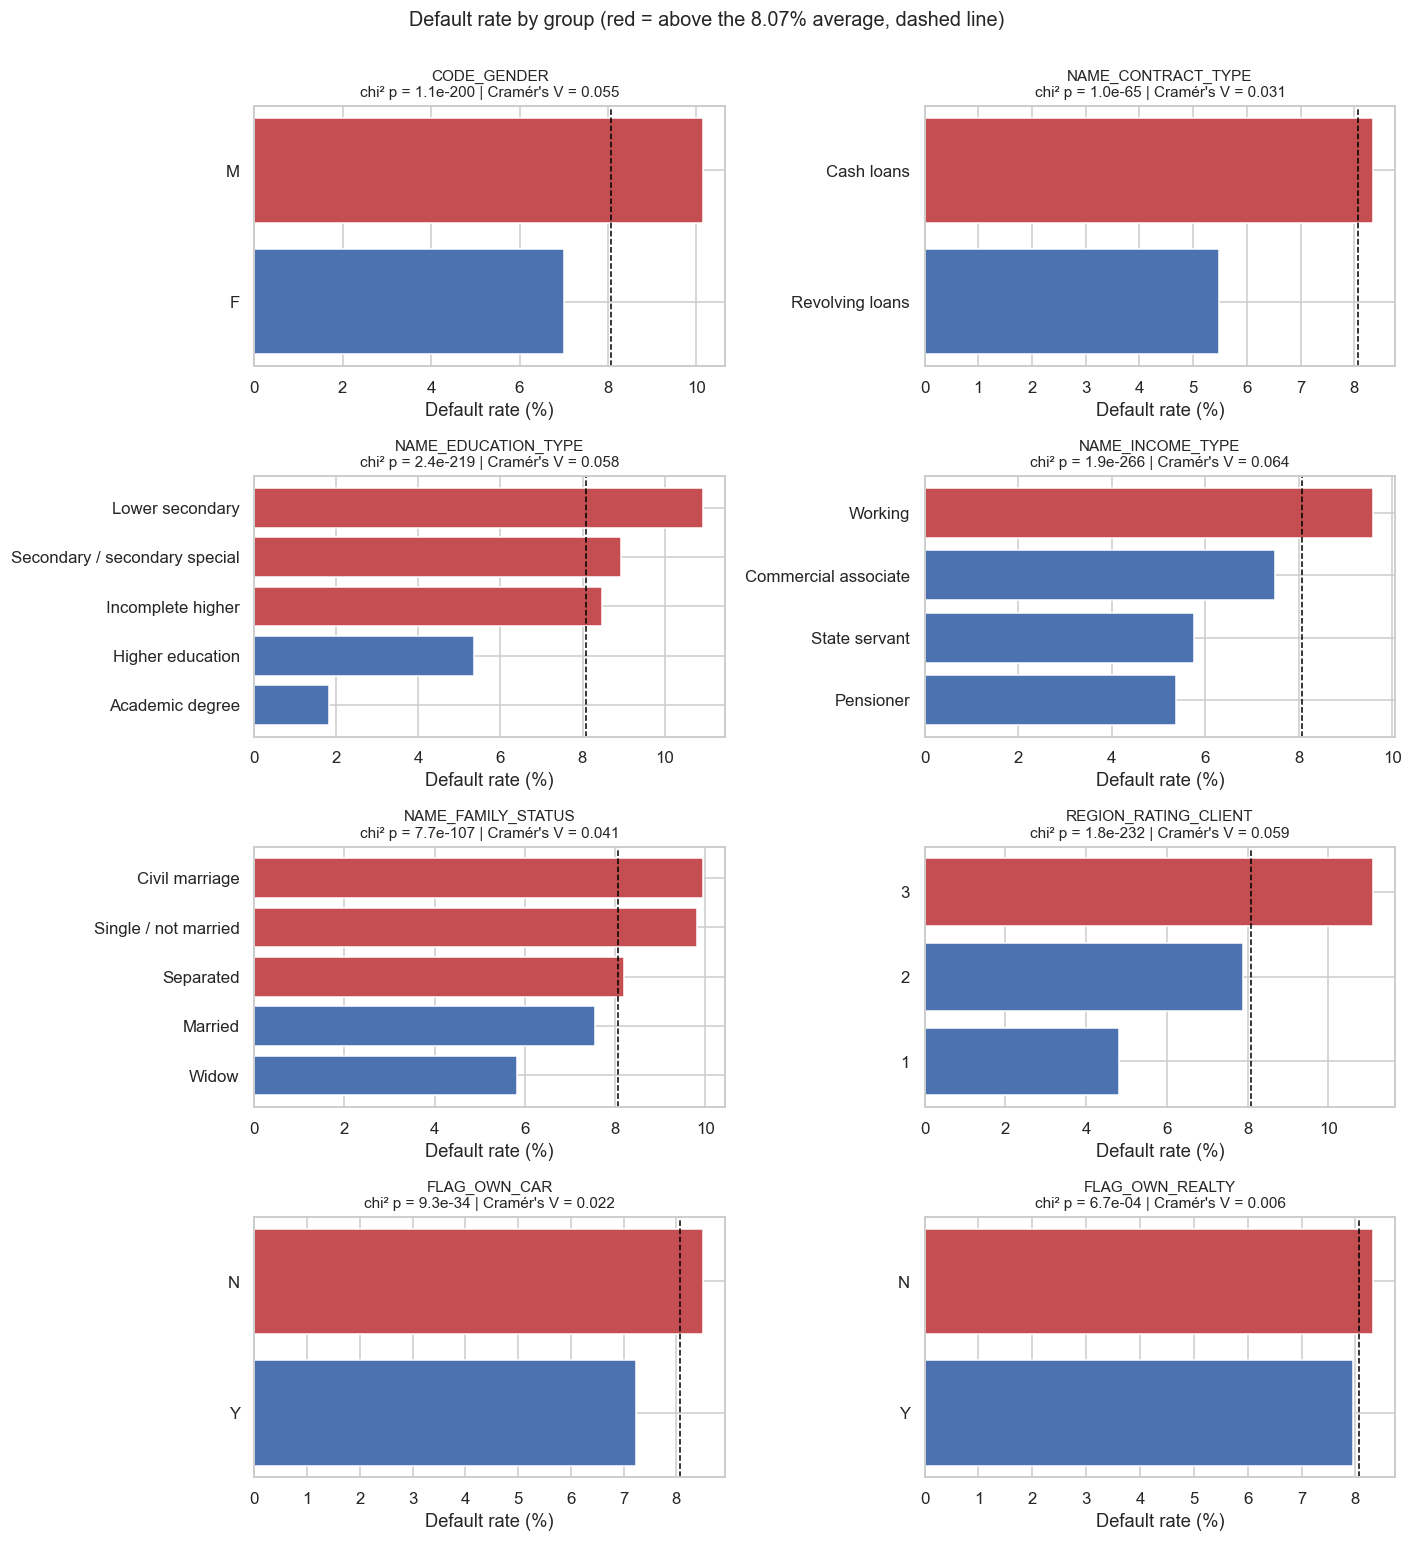

In [18]:
OVERALL = app[TARGET_COL].mean() * 100

def chi_square(col):
    table = pd.crosstab(app[col], app[TARGET_COL])
    chi2, p, dof, _ = stats.chi2_contingency(table)
    v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    return chi2, p, v

def plot_default_rate(col, ax, min_size=100, order=None):
    g = app.groupby(col)[TARGET_COL].agg(rate="mean", n="size")
    g = g[g["n"] >= min_size]                       # hide tiny groups (unreliable rates)
    g = g.reindex(order) if order else g.sort_values("rate")
    colors = ["#C44E52" if r * 100 > OVERALL else "#4C72B0" for r in g["rate"]]
    ax.barh(g.index.astype(str), g["rate"] * 100, color=colors)
    ax.axvline(OVERALL, color="black", ls="--", lw=1)
    chi2, p, v = chi_square(col)
    ax.set_title(f"{col}\nchi² p = {p:.1e} | Cramér's V = {v:.3f}", fontsize=10)
    ax.set_xlabel("Default rate (%)")

cat_cols = ["CODE_GENDER", "NAME_CONTRACT_TYPE", "NAME_EDUCATION_TYPE", "NAME_INCOME_TYPE",
            "NAME_FAMILY_STATUS", "REGION_RATING_CLIENT", "FLAG_OWN_CAR", "FLAG_OWN_REALTY"]
edu_order = ["Academic degree", "Higher education", "Incomplete higher", "Secondary / secondary special", "Lower secondary"]

fig, axes = plt.subplots(4, 2, figsize=(13, 14))
for ax, col in zip(axes.flat, cat_cols):
    plot_default_rate(col, ax, order=edu_order if col == "NAME_EDUCATION_TYPE" else None)
fig.suptitle("Default rate by group (red = above the 8.07% average, dashed line)", y=1.0, fontsize=13)
fig.tight_layout()
save(fig, "05_default_rate_by_category")
plt.show()

In [19]:
# Summary of the chi-square tests, strongest relationship first
tests = pd.DataFrame([(c, *chi_square(c)) for c in cat_cols + ["OCCUPATION_TYPE"]],
                     columns=["variable", "chi2", "p_value", "cramers_v"]).set_index("variable")
tests["significant (p<0.05)"] = tests["p_value"] < 0.05
tests.sort_values("cramers_v", ascending=False).style.format({"chi2": "{:,.0f}", "p_value": "{:.1e}", "cramers_v": "{:.3f}"})

,chi2,p_value,cramers_v,significant (p<0.05)
variable,,,,
OCCUPATION_TYPE,"1,403",3.8e-288,0.082,True
NAME_INCOME_TYPE,"1,253",1.9e-266,0.064,True
REGION_RATING_CLIENT,"1,067",1.8e-232,0.059,True
NAME_EDUCATION_TYPE,"1,019",2.4e-219,0.058,True
CODE_GENDER,921,1.1e-200,0.055,True
NAME_FAMILY_STATUS,505,7.7e-107,0.041,True
NAME_CONTRACT_TYPE,293,1.0e-65,0.031,True
FLAG_OWN_CAR,147,9.3e-34,0.022,True
FLAG_OWN_REALTY,12,6.7e-04,0.006,True


**Interpretation:**

| Variable | What the data shows |
|---|---|
| **Education** | Clear **ordinal pattern**: default falls from **10.9%** (lower secondary) to **5.4%** (higher education). Academic degrees default at 1.8%, but there are only 164 of them |
| **Income type** | Pensioners (5.4%) and state servants (5.8%) are safest; regular "Working" applicants default at 9.6% |
| **Region rating** | Risk rises steadily from region rating 1 (**4.8%**) to 3 (**11.1%**) |
| **Gender** | Men default more (**10.1%**) than women (**7.0%**) |
| **Contract type** | Cash loans (8.4%) are riskier than revolving loans (5.5%) |
| **Family status** | Single and civil-marriage applicants are slightly riskier (~9.8–9.9%) than married ones (7.6%) and widows (5.8%) |
| **Owns car / owns property** | Small differences (7.2% vs 8.5% for car; under 0.5 percentage points for property) |

- **All are statistically significant (p < 0.05)**, but every Cramér's V is **below 0.1**, so **each variable on its own is only a weak predictor.** Predicting default will require *combining* many weak signals, which is exactly what a machine-learning model does well.
- `OCCUPATION_TYPE` has the strongest association (V = 0.082). We plot it separately below because it has 18 categories.

**Responsible-AI note:** gender shows a real difference in default rates, but **using gender to decide who gets a loan is discriminatory** and is legally restricted in many countries. SecondLook will **exclude `CODE_GENDER` from the model**, keep it only for the **fairness audit** (do approval rates differ unfairly between men and women?), and never suggest it as something to change.

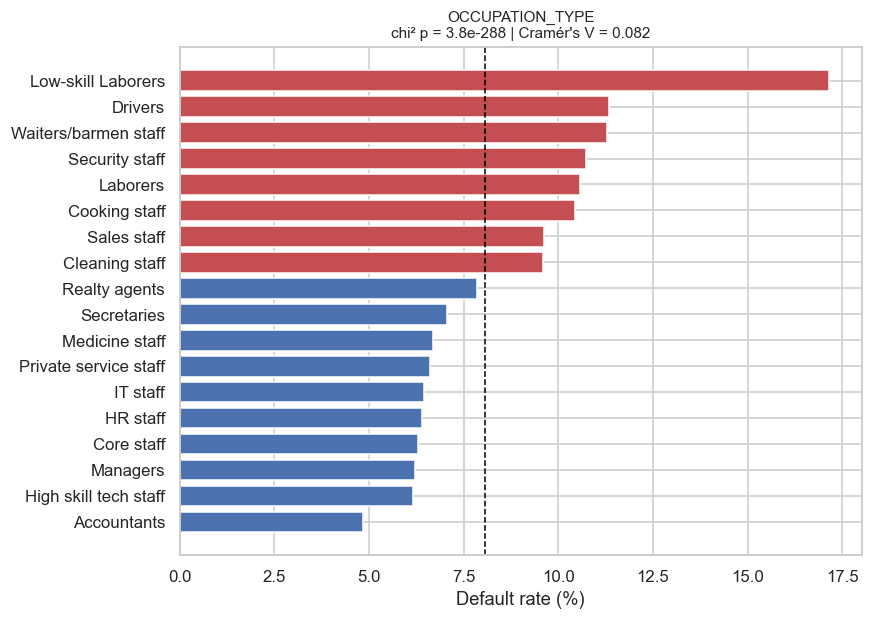

In [20]:
fig, ax = plt.subplots(figsize=(8, 6))
plot_default_rate("OCCUPATION_TYPE", ax)
save(fig, "06_default_rate_by_occupation")
plt.show()

**Interpretation:** default risk roughly follows job skill level: **accountants (4.8%)**, high-skill tech staff and managers (about 6.2%) at the low end; drivers (11.3%), waiters (11.3%) and **low-skill laborers (17.2%, more than double the average)** at the high end. Remember that 31% of applicants have no occupation recorded; we will treat "missing" as its own category.

## 9. Do defaulters look different on numerical variables?

We compare the distributions of key numeric variables for defaulters vs non-defaulters, then test whether the difference is real:

- **Welch's t-test** compares the **means** (doesn't assume equal variances).
- **Mann-Whitney U test** compares the **distributions** without assuming normality. It is safer for skewed data like income.

In [21]:
compare = ["AGE_YEARS", "YEARS_EMPLOYED", "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "AMT_INCOME_TOTAL", "AMT_CREDIT"]
rows = []
for col in compare:
    d = app.loc[app[TARGET_COL] == 1, col].dropna()
    r = app.loc[app[TARGET_COL] == 0, col].dropna()
    rows.append({"variable": col,
                 "mean (defaulted)": d.mean(), "mean (repaid)": r.mean(),
                 "median (defaulted)": d.median(), "median (repaid)": r.median(),
                 "t-test p": stats.ttest_ind(d, r, equal_var=False).pvalue,
                 "Mann-Whitney p": stats.mannwhitneyu(d, r).pvalue})
pd.DataFrame(rows).set_index("variable").style.format("{:,.3f}", subset=pd.IndexSlice[:, ["mean (defaulted)", "mean (repaid)", "median (defaulted)", "median (repaid)"]]).format("{:.1e}", subset=["t-test p", "Mann-Whitney p"])

,mean (defaulted),mean (repaid),median (defaulted),median (repaid),t-test p,Mann-Whitney p
variable,,,,,,
AGE_YEARS,40.752,44.184,39.102,43.469,0.0e+00,0.0e+00
YEARS_EMPLOYED,4.969,6.675,3.368,4.630,0.0e+00,0.0e+00
EXT_SOURCE_1,0.387,0.511,0.362,0.517,0.0e+00,0.0e+00
EXT_SOURCE_2,0.411,0.523,0.440,0.574,0.0e+00,0.0e+00
EXT_SOURCE_3,0.391,0.521,0.379,0.546,0.0e+00,0.0e+00
AMT_INCOME_TOTAL,"165,611.761","169,077.722","135,000.000","148,500.000",4.6e-01,1.0e-23
AMT_CREDIT,"557,778.528","602,648.282","497,520.000","517,788.000",2.7e-82,2.4e-22


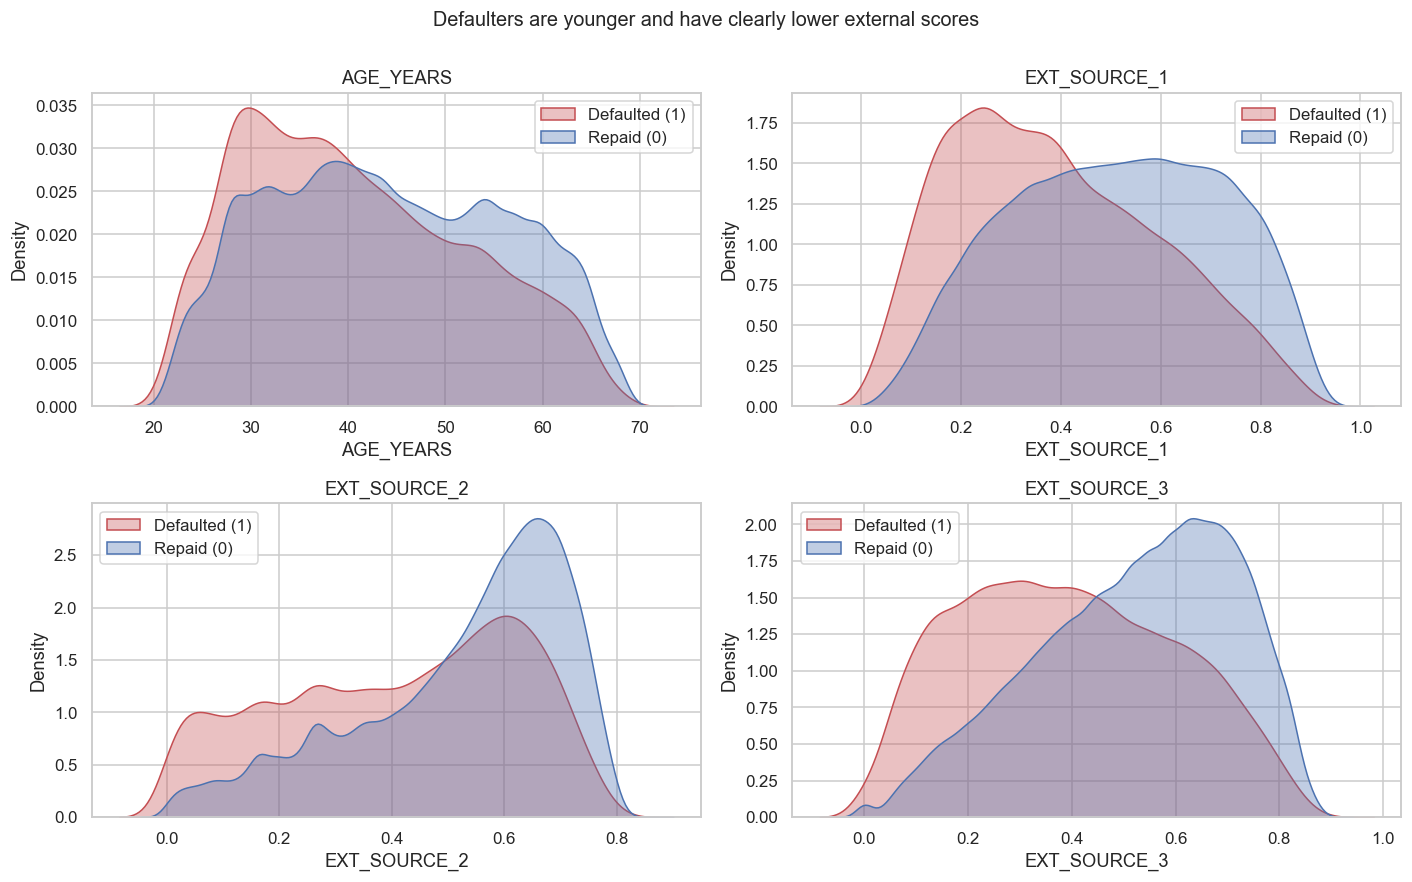

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.flat, ["AGE_YEARS", "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]):
    sns.kdeplot(data=app, x=col, hue=TARGET_COL, common_norm=False, fill=True, alpha=0.35,
                palette={0: "#4C72B0", 1: "#C44E52"}, ax=ax)
    ax.legend(["Defaulted (1)", "Repaid (0)"], title=None)
    ax.set_title(col)
fig.suptitle("Defaulters are younger and have clearly lower external scores", y=1.0, fontsize=13)
fig.tight_layout()
save(fig, "07_kde_age_extsource")
plt.show()

**Interpretation:**
- **External scores (`EXT_SOURCE_1/2/3`)** show the **clearest separation**: the median score for defaulters is about **0.36–0.44**, versus **0.52–0.57** for those who repaid. In the density plots the red curve (defaulted) sits visibly to the left. These will likely be the model's most important features.
- **Age:** defaulters are younger on average (**40.8 vs 44.2 years**).
- **Years employed:** defaulters have shorter job tenure (median **3.4 vs 4.6 years**).
- **Income: the most interesting result.** The **t-test is *not* significant (p = 0.47)**: average income is about the same for both groups. The Mann-Whitney test *is* significant, but the medians differ only slightly (135,000 vs 148,500). **Income alone barely predicts default.** What matters more is *how big the loan is relative to income*, which we explore in Section 10.3.
- This shows why we run **two tests**: the t-test compares means, which the extreme income outliers distort, while Mann-Whitney is robust to them.

## 10. Correlations and feature ideas

### 10.1 Which numeric variables correlate most with default?

**Pearson correlation** ranges from −1 to +1. Here a *negative* correlation means "higher value → **lower** risk".

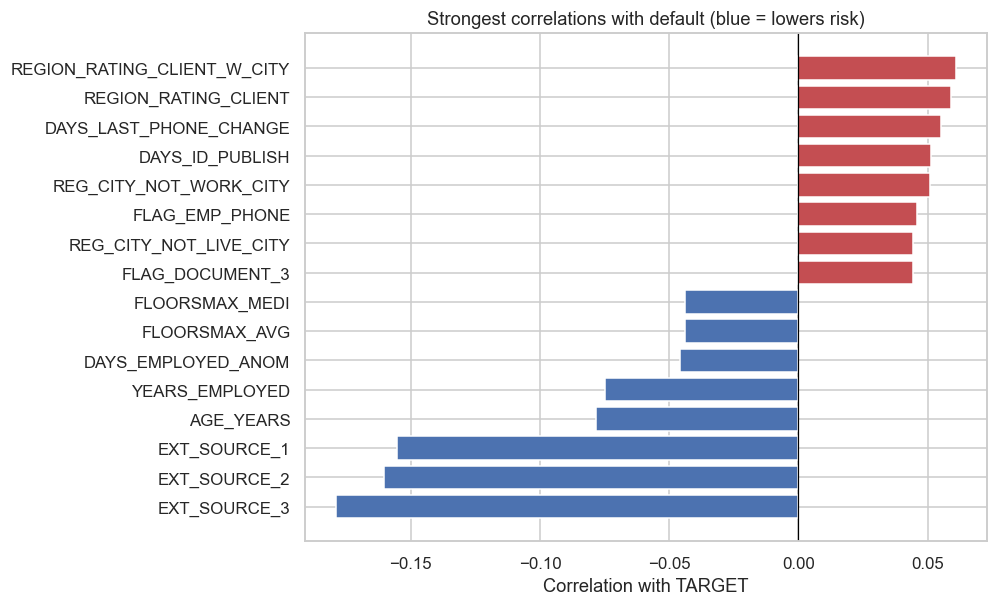

In [23]:
numeric = app.select_dtypes("number").drop(columns=[TARGET_COL, ID_COL])
corr = numeric.corrwith(app[TARGET_COL]).dropna()
corr = corr.drop(["DAYS_BIRTH", "DAYS_EMPLOYED"], errors="ignore")   # duplicates of AGE_YEARS / YEARS_EMPLOYED
top_corr = pd.concat([corr.nsmallest(8), corr.nlargest(8)]).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top_corr.index, top_corr.values, color=["#4C72B0" if v < 0 else "#C44E52" for v in top_corr])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Correlation with TARGET")
ax.set_title("Strongest correlations with default (blue = lowers risk)")
save(fig, "08_target_correlations")
plt.show()

**Interpretation:**
- The three **external scores are the strongest** (−0.16 to −0.18): higher score → lower risk.
- Next come **age** (−0.08) and **years employed** (−0.075): older, longer-employed applicants are safer.
- On the risk-increasing side: **region rating** (+0.06), how recently the applicant **changed phone number** (`DAYS_LAST_PHONE_CHANGE`) or **ID document** (`DAYS_ID_PUBLISH`), and living or working in a **different city** from their registered address (`REG_CITY_NOT_WORK_CITY`).
- **All correlations are weak (|r| < 0.2).** No single column predicts default well. This confirms the chi-square finding: the model's job is to **combine many weak signals.**

### 10.2 Are the predictors related to each other? (multicollinearity)

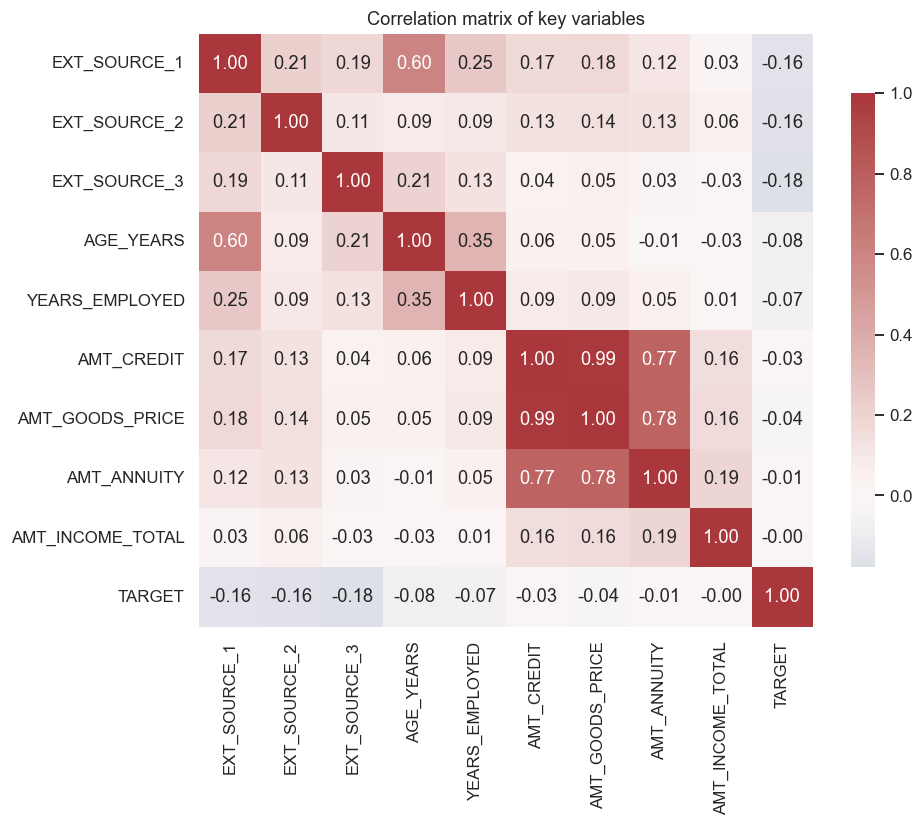

In [24]:
cols = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "AGE_YEARS", "YEARS_EMPLOYED",
        "AMT_CREDIT", "AMT_GOODS_PRICE", "AMT_ANNUITY", "AMT_INCOME_TOTAL", TARGET_COL]
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(app[cols].corr(), annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax, cbar_kws={"shrink": 0.8})
ax.set_title("Correlation matrix of key variables")
save(fig, "09_correlation_heatmap")
plt.show()

**Interpretation:**
- **`AMT_CREDIT` and `AMT_GOODS_PRICE` are almost identical (r = 0.99):** the loan amount is basically the price of the item being financed. Keeping both adds no new information, but their **ratio** might (see below).
- **`EXT_SOURCE_1` is correlated with age (r = 0.60)**, so part of what that score measures is age. The three external scores are only weakly related to each other (0.11–0.21), so each brings **different** information, and it's worth keeping all three.
- **Decision:** drop `AMT_GOODS_PRICE` as a raw feature for the linear model, and keep all three external scores plus their average.

### 10.3 Engineered features: ratios that tell a better story

Raw amounts don't say much on their own: a ₱500,000 loan is easy for a high earner and heavy for a low earner. Lenders think in **ratios**, so we test three of them, plus the average external score and age groups. For each, we split applicants into five equal-size groups (quintiles) and compare default rates.

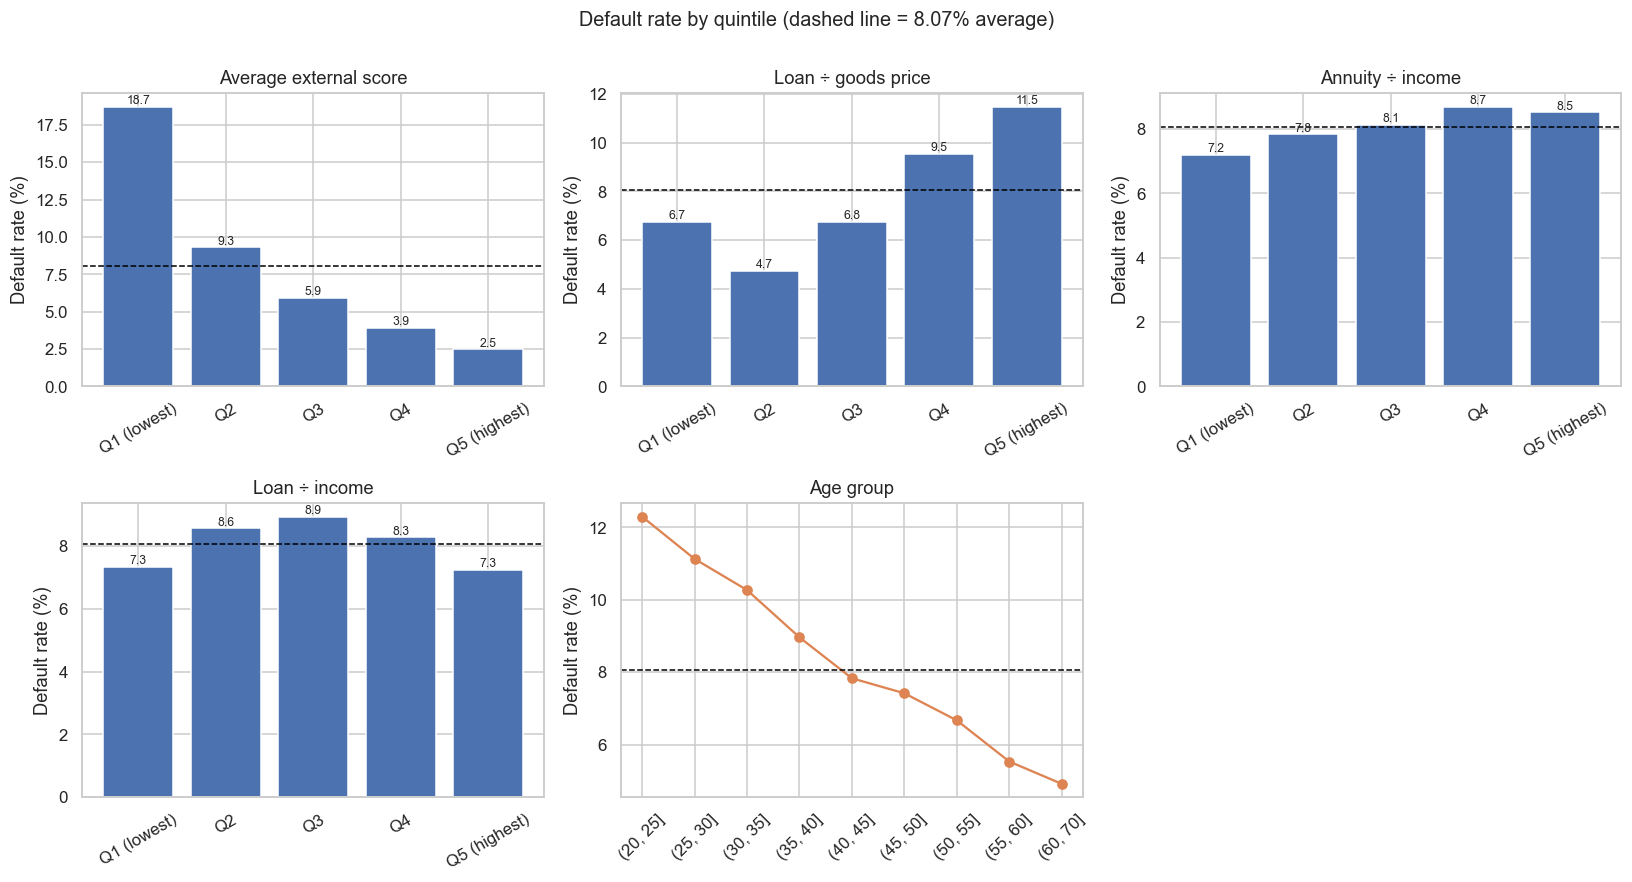

Default rate by age group (%):
AGE_GROUP
(20, 25]   12.30
(25, 30]   11.10
(30, 35]   10.30
(35, 40]    9.00
(40, 45]    7.80
(45, 50]    7.40
(50, 55]    6.70
(55, 60]    5.50
(60, 70]    4.90


In [25]:
app["CREDIT_TO_INCOME"] = app["AMT_CREDIT"] / app["AMT_INCOME_TOTAL"]     # loan size vs income
app["ANNUITY_TO_INCOME"] = app["AMT_ANNUITY"] / app["AMT_INCOME_TOTAL"]   # repayment burden
app["CREDIT_TO_GOODS"] = app["AMT_CREDIT"] / app["AMT_GOODS_PRICE"]       # loan vs item price (>1 = borrowing extra)
app["EXT_SOURCE_MEAN"] = app[["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]].mean(axis=1)
app["AGE_GROUP"] = pd.cut(app["AGE_YEARS"], [20, 25, 30, 35, 40, 45, 50, 55, 60, 70])

def rate_by_quintile(col):
    q = pd.qcut(app[col], 5, labels=["Q1 (lowest)", "Q2", "Q3", "Q4", "Q5 (highest)"], duplicates="drop")
    return app.groupby(q, observed=True)[TARGET_COL].mean() * 100

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
panels = [("EXT_SOURCE_MEAN", "Average external score"), ("CREDIT_TO_GOODS", "Loan ÷ goods price"),
          ("ANNUITY_TO_INCOME", "Annuity ÷ income"), ("CREDIT_TO_INCOME", "Loan ÷ income")]
for ax, (col, title) in zip(axes.flat, panels):
    r = rate_by_quintile(col)
    ax.bar(r.index.astype(str), r.values, color="#4C72B0")
    ax.axhline(OVERALL, color="black", ls="--", lw=1)
    ax.set_title(title); ax.set_ylabel("Default rate (%)"); ax.tick_params(axis="x", rotation=30)
    ax.bar_label(ax.containers[0], fmt="%.1f", fontsize=8)

age_rate = app.groupby("AGE_GROUP", observed=True)[TARGET_COL].mean() * 100
axes[1, 1].plot(age_rate.index.astype(str), age_rate.values, marker="o", color="#DD8452")
axes[1, 1].axhline(OVERALL, color="black", ls="--", lw=1)
axes[1, 1].set_title("Age group"); axes[1, 1].set_ylabel("Default rate (%)"); axes[1, 1].tick_params(axis="x", rotation=45)
axes[1, 2].axis("off")
fig.suptitle("Default rate by quintile (dashed line = 8.07% average)", y=1.0, fontsize=13)
fig.tight_layout()
save(fig, "10_engineered_features")
plt.show()

print("Default rate by age group (%):"); print(age_rate.round(1).to_string())

**Interpretation:**
- **Average external score is the single most powerful signal found so far.** The lowest-score fifth of applicants defaults at **18.7%**, the highest-score fifth at only **2.5%**, a **7.5× difference**. This is the backbone of the risk model.
- **Loan ÷ goods price:** applicants borrowing *more* than the item costs (the top fifth, ratio above 1.21) default at **11.5%**, versus 4.7% for those borrowing roughly the item's price. Borrowing extra cash on top of the purchase is a risk signal.
- **Annuity ÷ income:** a heavier repayment burden means more risk (**7.2% → 8.5–8.7%**), a moderate but steady effect.
- **Loan ÷ income:** an **inverted U**. The middle groups are riskiest (about 8.9%) and both extremes are safer. A linear model would miss this, which is one reason we will use LightGBM.
- **Age:** default falls steadily with age, from **12.3% (20–25)** to **4.9% (60–70)**.

**Why this matters for SecondLook:** these ratios are **things an applicant can actually change**. Lowering the loan amount, choosing a longer term (smaller annuity) or borrowing closer to the item's price all move the ratios toward safer groups. They will become the main levers of the **"path to approval"** feature. Age and gender are never used as levers.

## 11. Credit history tables: does past behaviour predict default?

The main table is a snapshot at application time. The history tables show **behaviour over time**. To use them, we **aggregate** each one to one row per applicant (like SQL `GROUP BY`) and **merge** the result onto the main table (like a SQL `LEFT JOIN`). We load only the columns we need, because these tables are large.

In [26]:
target = app[[ID_COL, TARGET_COL]]

# --- 11.1 Credit bureau: loans at OTHER lenders
bureau = load_table("bureau", usecols=[ID_COL, "CREDIT_ACTIVE"])
n_bureau = bureau.groupby(ID_COL).size().rename("N_BUREAU_LOANS")
b = target.merge(n_bureau, on=ID_COL, how="left").fillna({"N_BUREAU_LOANS": 0})

print(f"Bureau rows: {len(bureau):,}")
print(f"Applicants with at least one bureau record: {(b['N_BUREAU_LOANS'] > 0).mean():.1%}")
print(f"Median bureau loans per applicant: {b['N_BUREAU_LOANS'].median():.0f}")
print("\nStatus of bureau loans:"); print((bureau["CREDIT_ACTIVE"].value_counts(normalize=True) * 100).round(1).to_string())
thin = b.groupby(b["N_BUREAU_LOANS"].eq(0).map({True: "No bureau record (thin file)", False: "Has bureau history"}))[TARGET_COL].agg(["mean", "size"])
thin["mean"] *= 100
thin.columns = ["default rate %", "applicants"]
display(thin)
del bureau

Bureau rows: 1,716,428
Applicants with at least one bureau record: 85.7%
Median bureau loans per applicant: 4

Status of bureau loans:
CREDIT_ACTIVE
Closed     62.90
Active     36.70
Sold        0.40
Bad debt    0.00


,default rate %,applicants
N_BUREAU_LOANS,,
Has bureau history,7.73,263491
No bureau record (thin file),10.12,44020


**Interpretation:** 85.7% of applicants have a record at other lenders (median 4 previous loans; about 63% of those loans are closed and 37% still active). But **14.3% have no bureau record at all: true thin-file borrowers.** Their default rate is **10.1%**, versus **7.7%** for applicants with history.

**This is the core of the SecondLook business case:** thin-file applicants *are* riskier on average, which is why lenders decline them. But 90% of them still repay. Our job is to find that 90% using the other signals.

Previous applications: 1,670,214
NAME_CONTRACT_STATUS
Approved       62.10
Canceled       18.90
Refused        17.40
Unused offer    1.60



Installment rows: 13,605,401   Share of installments paid late: 8.4%


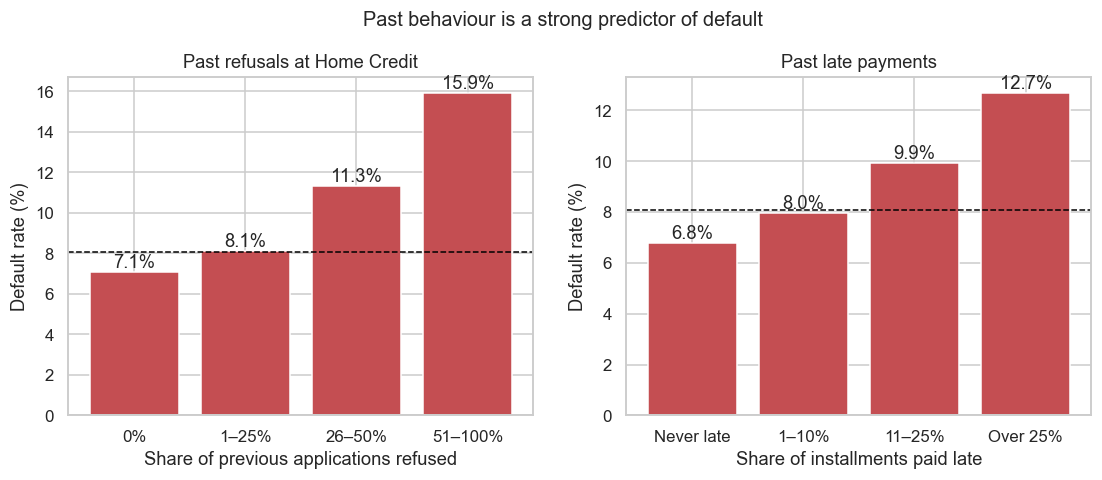

In [27]:
# --- 11.2 Previous Home Credit applications: approvals vs refusals
prev = load_table("previous_application", usecols=[ID_COL, "NAME_CONTRACT_STATUS"])
print(f"Previous applications: {len(prev):,}")
print((prev["NAME_CONTRACT_STATUS"].value_counts(normalize=True) * 100).round(1).to_string())

refused_share = prev.assign(refused=prev["NAME_CONTRACT_STATUS"].eq("Refused")).groupby(ID_COL)["refused"].mean()
p = target.merge(refused_share.rename("REFUSED_SHARE"), on=ID_COL, how="left")
groups = pd.cut(p["REFUSED_SHARE"], [-0.01, 0, 0.25, 0.5, 1.0], labels=["0%", "1–25%", "26–50%", "51–100%"])
prev_rate = p.groupby(groups, observed=True)[TARGET_COL].mean() * 100
del prev

# --- 11.3 Installment payments: how often did they pay late?
inst = load_table("installments_payments", usecols=[ID_COL, "DAYS_INSTALMENT", "DAYS_ENTRY_PAYMENT"])
inst["LATE"] = inst["DAYS_ENTRY_PAYMENT"] > inst["DAYS_INSTALMENT"]      # paid after the due date
late_share = inst.groupby(ID_COL)["LATE"].mean()
i = target.merge(late_share.rename("LATE_SHARE"), on=ID_COL, how="left")
groups = pd.cut(i["LATE_SHARE"], [-0.01, 0, 0.10, 0.25, 1.0], labels=["Never late", "1–10%", "11–25%", "Over 25%"])
late_rate = i.groupby(groups, observed=True)[TARGET_COL].mean() * 100
print(f"\nInstallment rows: {len(inst):,}   Share of installments paid late: {inst['LATE'].mean():.1%}")
del inst

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, rate, title, xlabel in [(axes[0], prev_rate, "Past refusals at Home Credit", "Share of previous applications refused"),
                                 (axes[1], late_rate, "Past late payments", "Share of installments paid late")]:
    bars = ax.bar(rate.index.astype(str), rate.values, color="#C44E52")
    ax.bar_label(bars, fmt="%.1f%%")
    ax.axhline(OVERALL, color="black", ls="--", lw=1)
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel("Default rate (%)")
fig.suptitle("Past behaviour is a strong predictor of default", y=1.03, fontsize=13)
save(fig, "11_history_behaviour")
plt.show()

**Interpretation:**
- **Previous refusals:** about 62% of past applications were approved and 17% refused. Applicants who were refused in **more than half** of their previous applications default at **15.9%**, more than double those never refused (**7.1%**).
- **Late payments:** about 8.4% of all past installments were paid late. Applicants who were **never late** default at **6.8%**; those late on **more than 25%** of installments default at **12.7%**.
- **Past behaviour is one of the strongest signals we have**, comparable to the external scores. In Step 3 we will build many more of these per-applicant summaries with SQL (counts, averages, late-payment rates, recent vs older behaviour) from all six history tables.

## 12. Key insights and what we do next

### What we learned

| # | Insight | Evidence |
|---|---|---|
| 1 | **Defaults are rare: 8.07%** | 24,825 of 307,511 applicants |
| 2 | **External scores are the strongest predictors** | Lowest-score fifth defaults at 18.7% vs 2.5% for the highest fifth |
| 3 | **Past behaviour matters** | Over 50% past refusals → 15.9% default; frequent late payers → 12.7% |
| 4 | **Thin-file applicants are riskier, but most still repay** | No bureau record → 10.1% default (vs 7.7%), so 90% repay |
| 5 | **Loan structure matters more than income** | Income barely differs between groups (t-test p = 0.47); borrowing above the item price → 11.5% default |
| 6 | **Younger, less-educated, shorter-tenure applicants are riskier** | Age 20–25: 12.3% vs 60–70: 4.9%; lower secondary 10.9% vs higher education 5.4% |
| 7 | **Every single factor is weak on its own** | All correlations below 0.2 and all Cramér's V below 0.1, so a model must combine them |
| 8 | **The data needs cleaning** | 18% placeholder employment values, 41 columns over 50% missing, a 117M income error |

### Decisions for the next steps

| Area | Decision |
|---|---|
| **Cleaning (Step 3)** | Replace `DAYS_EMPLOYED = 365243` with missing + flag; convert days to years; cap income at the 99.9th percentile; set gender "XNA" to missing |
| **Missing values** | Keep rows; LightGBM handles missing natively; impute + add missing-flags for logistic regression |
| **Features (Step 3)** | Ratios (loan/income, annuity/income, loan/goods), average external score, and SQL aggregates from all history tables (counts, refusals, late-payment rates) |
| **Modelling (Step 4)** | Stratified train/test split; class weights; evaluate with **ROC AUC, precision and recall**, not accuracy; LightGBM to capture non-linear patterns like the inverted-U loan-to-income effect |
| **Responsible AI** | **Exclude gender from the model**; use it (and age) only in the fairness audit; never suggest unchangeable attributes in the path to approval |
| **App** | Use loan amount, term (annuity) and loan-to-goods ratio as the main "path to approval" levers |

All charts from this notebook are saved in `reports/figures/` for the README and the pitch.